In [1]:
import numpy as np, pandas as pd, sklearn
print("Setup OK", pd.__version__, sklearn.__version__)

Setup OK 2.3.3 1.7.2


# Lab 3: Ticket Escalation Classification

In this lab I build and compare classifiers that predict whether a service ticket gets escalated. The goal isn't just a high score. I want to pick metrics and a decision threshold that reflect what mistakes actually cost.

## 1. Setup and loading the data

First I import all the libraries I'll need for the whole lab, so everything is in one place at the top.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

I load the CSV and take a first look: how many rows and columns there are, what the first few tickets look like, and the data types of each column.

In [3]:
df = pd.read_csv("classification_escalation.csv")
print("Shape (rows, columns):", df.shape)
display(df.head())
print()
df.info()

Shape (rows, columns): (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    object 
 3   channel                 900 non-null    object 
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 42.3+ KB


The lab says some predictors have missing values on purpose. Here I count them per column, and also show them as a percentage so it's clear how big the problem is. I'll handle them later inside the preprocessing pipeline.

In [4]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
})
display(missing)

,missing_count,missing_percent
complexity_score,0,0.0
team_experience_years,31,3.4
priority,18,2.0
channel,0,0.0
customer_tenure_months,22,2.4
escalated,0,0.0


Next I check how common escalations are. If one class is much rarer than the other, plain accuracy can look good while the model misses most escalated tickets.

In [5]:
print("Proportion of each class:")
print(df["escalated"].value_counts(normalize=True).rename("proportion"))
print()
print("Counts:")
print(df["escalated"].value_counts().rename("count"))

Proportion of each class:
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64

Counts:
escalated
0    714
1    186
Name: count, dtype: int64


A quick statistical summary of the numeric columns, plus the categories in the text columns, to see ranges and spot anything odd.

In [6]:
display(df.describe())
for col in ["priority", "channel"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

,complexity_score,team_experience_years,customer_tenure_months,escalated
count,900.000000,869.000000,878.000000,900.000000
mean,5.433333,4.443268,22.553075,0.206667
std,2.834909,2.137840,14.888236,0.405139
min,1.000000,0.000000,0.900000,0.000000
25%,3.000000,2.900000,11.400000,0.000000
50%,5.000000,4.400000,19.550000,0.000000
75%,8.000000,5.900000,30.150000,0.000000
max,10.000000,11.800000,97.400000,1.000000



priority:
priority
low       434
medium    306
high      142
NaN        18
Name: count, dtype: int64

channel:
channel
email    424
web      304
phone    172
Name: count, dtype: int64


**What I found:** The dataset has 900 tickets and 5 predictors. Only three columns have missing values (between 2% and 3.4%), so imputation is enough and no rows need dropping. About 20.7% of tickets are escalated, so the classes are imbalanced. A model that always predicts "not escalated" would already be 79.3% accurate, which is why I'll look at precision, recall and F1 and not accuracy alone.

## 2. Problem framing

This is a **classification** problem because the thing I'm predicting, `escalated`, is a category (yes or no), not a number on a scale. Specifically it's binary classification with two outcomes.

The **positive class is 1 = escalated**. I chose this because escalations are the rare and costly event the support team actually wants to catch. So when I talk about recall later, I mean "of all the tickets that really were escalated, how many did the model find?"

## 3. Train/test split

First I split the table into the predictors (X) and the target (y). Then I hold out 25% of the tickets as a test set that the models never see during training. I use `stratify=y` so both sets keep the same share of escalated tickets (about 20.7%), and `random_state=42` so the split is the same every time I run it.

In [7]:
X = df.drop(columns="escalated")
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print()
print("Escalation rate in each set:")
print("full data:", round(y.mean(), 4))
print("train    :", round(y_train.mean(), 4))
print("test     :", round(y_test.mean(), 4))

Train: (675, 5)  Test: (225, 5)

Escalation rate in each set:
full data: 0.2067
train    : 0.2074
test     : 0.2044


I split the data *before* filling in missing values or scaling anything. If I computed medians or averages on the whole dataset first, information from the test set would leak into training and make my results look better than they really are. Doing the cleaning inside a pipeline fitted only on the training data avoids that.

## 4. Preprocessing

The numeric and categorical columns need different treatment, so I list them separately first.

In [8]:
numeric_features = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_features = ["priority", "channel"]

print("Numeric    :", numeric_features)
print("Categorical:", categorical_features)

Numeric    : ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical: ['priority', 'channel']


For the numeric columns I fill missing values with the **median** (it isn't pulled around by outliers like the long tail in tenure) and then **scale** them so they're on a similar footing. Scaling matters for logistic regression and especially k-NN, which relies on distances.

For the categorical columns I fill missing values with the **most frequent** category and then **one-hot encode**, which turns each category into its own 0/1 column. I set `handle_unknown="ignore"` so a category not seen in training won't crash the model.

`ColumnTransformer` applies the right pipeline to the right columns. Because it's fitted only on training data, nothing leaks from the test set.

In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


Quick sanity check: I fit the preprocessor on the training data only, transform both sets, and confirm there are no missing values left and that the column count makes sense.

In [10]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Train shape after preprocessing:", X_train_prep.shape)
print("Test shape after preprocessing :", X_test_prep.shape)
print("Any NaN left in train?", np.isnan(X_train_prep).any())
print("Any NaN left in test? ", np.isnan(X_test_prep).any())
print()
print("Column names:")
print(list(preprocessor.get_feature_names_out()))

Train shape after preprocessing: (675, 9)
Test shape after preprocessing : (225, 9)
Any NaN left in train? False
Any NaN left in test?  False

Column names:
['num__complexity_score', 'num__team_experience_years', 'num__customer_tenure_months', 'cat__priority_high', 'cat__priority_low', 'cat__priority_medium', 'cat__channel_email', 'cat__channel_phone', 'cat__channel_web']


## 5. Models

I'm comparing four classifiers. Each one is wrapped in a pipeline together with the preprocessor, so the same cleaning steps are applied consistently and are only learned from the training data.

- **Majority-class baseline:** always predicts "not escalated". It's the bar every real model has to beat.
- **Logistic regression:** a simple, interpretable model that outputs a probability of escalation.
- **LDA (Linear Discriminant Analysis):** another linear model that assumes each class is roughly bell-shaped with the same spread.
- **k-NN (k=15):** looks at the 15 most similar training tickets and goes with the majority.

In [11]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15),
}

pipelines = {
    name: Pipeline([("prep", preprocessor), ("model", model)])
    for name, model in models.items()
}

print("Models defined:", list(pipelines.keys()))

Models defined: ['Majority baseline', 'Logistic regression', 'LDA', 'k-NN (k=15)']


Now I train all four on the training set only. The test set stays untouched until I evaluate.

In [12]:
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print("Fitted:", name)

Fitted: Majority baseline
Fitted: Logistic regression
Fitted: LDA
Fitted: k-NN (k=15)


A quick peek at what each model predicts on the test set: how many tickets it flags as escalated, compared with the 46 or so that really were.

In [13]:
print("Actual escalated in test set:", int(y_test.sum()))
print()
for name, pipe in pipelines.items():
    preds = pipe.predict(X_test)
    print(f"{name:20s} predicted escalated: {int(preds.sum())}")

Actual escalated in test set: 46

Majority baseline    predicted escalated: 0
Logistic regression  predicted escalated: 12
LDA                  predicted escalated: 12
k-NN (k=15)          predicted escalated: 8


## 6. Model comparison

I score every model on the test set using accuracy, precision, recall, F1 and ROC-AUC. Escalated (1) is the positive class. ROC-AUC needs probability scores, and all four models can produce them (the baseline just gives a constant, so its AUC is 0.5).

In [14]:
rows = []
for name, pipe in pipelines.items():
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probs),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.796,0.00,0.000,0.000,0.500
Logistic regression,0.822,0.75,0.196,0.310,0.811
LDA,0.822,0.75,0.196,0.310,0.809
k-NN (k=15),0.796,0.50,0.087,0.148,0.705


**Reading the table:** Accuracy is misleading here. The baseline gets 79.6% by never predicting an escalation, and logistic regression and LDA only improve on it to 82.2%. Logistic regression and LDA perform almost identically, with precision 0.75, recall 0.196 and F1 0.31. They are precise but miss most real escalations, because at the default 0.5 cutoff they only flag tickets they're very sure about. k-NN is the weakest (recall 0.087, AUC 0.705). The ROC-AUC of about 0.81 for the linear models suggests the probability scores are useful, so the problem is mainly the threshold, which I look at next.

## 7. Logistic regression: confusion matrix and ROC curve

I pick logistic regression for a closer look. The confusion matrix shows exactly where it is right and wrong at the default 0.5 threshold. The rows are the true class and the columns are what the model predicted.

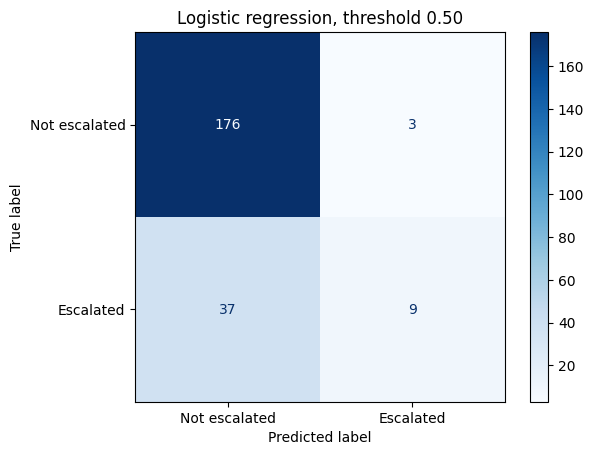

TN=176  FP=3  FN=37  TP=9


In [15]:
lr_pipe = pipelines["Logistic regression"]
lr_preds = lr_pipe.predict(X_test)

cm = confusion_matrix(y_test, lr_preds)
ConfusionMatrixDisplay(cm, display_labels=["Not escalated", "Escalated"]).plot(cmap="Blues")
plt.title("Logistic regression, threshold 0.50")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

The ROC curve shows the trade-off between catching real escalations (true positive rate) and raising false alarms (false positive rate) as the threshold moves. The dashed diagonal is a model that guesses at random, so the further the curve bows toward the top-left, the better.

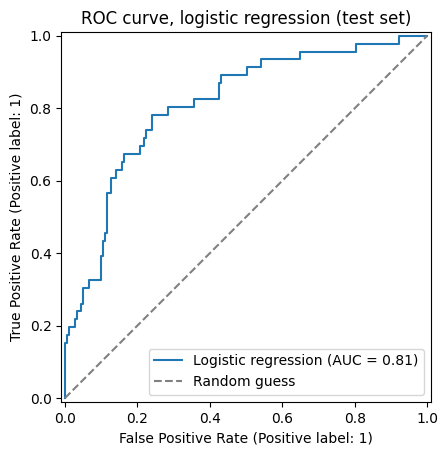

In [16]:
RocCurveDisplay.from_estimator(lr_pipe, X_test, y_test, name="Logistic regression")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.legend()
plt.title("ROC curve, logistic regression (test set)")
plt.show()

**Reading the matrix:** At the default 0.5 threshold the model made only 3 false alarms but missed 37 of the 46 real escalations. It is very cautious. Since a missed escalation is likely far more costly than an unnecessary one, this threshold looks too high, so I explore lower thresholds next.

## 8. Threshold analysis

The model outputs a probability of escalation for each ticket. Instead of always using 0.50 as the cutoff, I try six thresholds from 0.20 to 0.70 and record precision, recall, F1 and the raw counts of false positives (FP) and false negatives (FN) for each. A lower threshold flags more tickets, so I expect recall to rise and precision to fall.

In [17]:
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

rows = []
for t in thresholds:
    preds_t = (lr_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_t).ravel()
    rows.append({
        "Threshold": t,
        "Flagged": int(preds_t.sum()),
        "Precision": precision_score(y_test, preds_t, zero_division=0),
        "Recall": recall_score(y_test, preds_t),
        "F1": f1_score(y_test, preds_t, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })

threshold_table = pd.DataFrame(rows).set_index("Threshold").round(3)
threshold_table

,Flagged,Precision,Recall,F1,TP,FP,FN,TN
Threshold,,,,,,,,
0.2,84,0.429,0.783,0.554,36,48,10,131
0.3,51,0.549,0.609,0.577,28,23,18,156
0.4,21,0.571,0.261,0.358,12,9,34,170
0.5,12,0.750,0.196,0.310,9,3,37,176
0.6,3,1.000,0.065,0.122,3,0,43,179
0.7,0,0.000,0.000,0.000,0,0,46,179


A quick plot makes the trade-off easier to see: as the threshold goes down, recall climbs while precision drops.

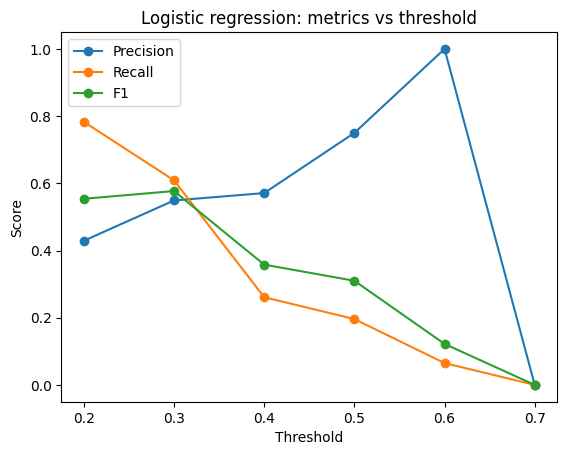

In [18]:
plt.plot(threshold_table.index, threshold_table["Precision"], marker="o", label="Precision")
plt.plot(threshold_table.index, threshold_table["Recall"], marker="o", label="Recall")
plt.plot(threshold_table.index, threshold_table["F1"], marker="o", label="F1")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Logistic regression: metrics vs threshold")
plt.legend()
plt.show()

**Reading the table:** Lowering the threshold makes the model flag more tickets. Recall climbs from 0.196 at 0.50 to 0.783 at 0.20, and missed escalations (FN) drop from 37 to 10. The price is more false alarms: FP rises from 3 to 48 and precision falls from 0.75 to 0.43. At 0.60 precision is 1.0 but only 3 tickets are flagged, so that number is not reliable. At 0.70 no tickets are flagged at all. F1 is highest at 0.30, but F1 weights both error types equally, so I use a cost function next.

## 9. Cost-based threshold choice

Not all mistakes cost the same. A missed escalation (FN) is probably much worse than an unnecessary escalation (FP), so I use the lab's illustrative cost of 5 per FN and 1 per FP. The best threshold is the one with the lowest total cost on the test set. The costs are made-up numbers for this exercise, not real business figures.

In [19]:
cost_fn, cost_fp = 5, 1

threshold_table["Cost"] = cost_fn * threshold_table["FN"] + cost_fp * threshold_table["FP"]
display(threshold_table[["FP", "FN", "Cost"]])

best_t = threshold_table["Cost"].idxmin()
print("Threshold with the lowest cost:", best_t)
print("Lowest cost:", threshold_table["Cost"].min())

,FP,FN,Cost
Threshold,,,
0.2,48,10,98
0.3,23,18,113
0.4,9,34,179
0.5,3,37,188
0.6,0,43,215
0.7,0,46,230


Threshold with the lowest cost: 0.2
Lowest cost: 98


Plotting the cost makes it easy to see where the minimum is.

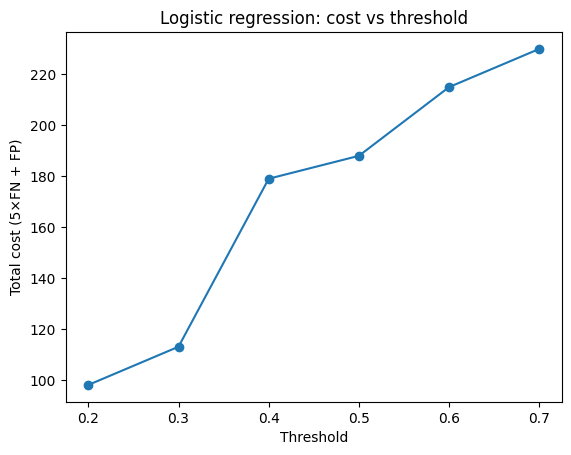

In [20]:
plt.plot(threshold_table.index, threshold_table["Cost"], marker="o")
plt.xlabel("Threshold")
plt.ylabel("Total cost (5×FN + FP)")
plt.title("Logistic regression: cost vs threshold")
plt.show()

### Expected cost with posterior 0.30

Let p = P(escalated | x) = 0.30.

- **If I escalate:** I'm wrong when the ticket was not escalated, which has probability 1 − p = 0.70. That costs 1 (a false positive). Expected cost = 0.70 × 1 = **0.70**.
- **If I do not escalate:** I'm wrong when the ticket was escalated, which has probability p = 0.30. That costs 5 (a false negative). Expected cost = 0.30 × 5 = **1.50**.

Escalating is cheaper (0.70 < 1.50), so I should escalate this ticket, even though the probability is below 0.50.

### Cost-sensitive threshold

I should escalate whenever the expected cost of escalating is lower than the expected cost of not escalating:

(1 − p) × C_FP < p × C_FN

Solving for p:

p > C_FP / (C_FP + C_FN) = 1 / (1 + 5) = **1/6 ≈ 0.167**

So the theoretically best threshold is about 0.167, not 0.50. This agrees with the finding that lower thresholds work better here.

## 10. Cross-validation and tuning k-NN

So far I used k=15 for k-NN without checking whether it's a good choice. Here I use stratified 5-fold cross-validation on the **training set only** to compare k = 5, 9, 15, 21 and 31, scoring each by F1. The test set stays untouched. Because the preprocessor is inside the pipeline, imputing and scaling are re-learned inside each fold, so nothing leaks between folds.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier())
])

param_grid = {"model__n_neighbors": [5, 9, 15, 21, 31]}

grid = GridSearchCV(knn_pipe, param_grid, scoring="f1", cv=cv)
grid.fit(X_train, y_train)

knn_cv = pd.DataFrame({
    "k": [5, 9, 15, 21, 31],
    "Mean CV F1": grid.cv_results_["mean_test_score"],
    "Std": grid.cv_results_["std_test_score"],
}).set_index("k").round(3)
display(knn_cv)

print("Best k:", grid.best_params_["model__n_neighbors"])
print("Best CV F1:", round(grid.best_score_, 3))

,Mean CV F1,Std
k,,
5,0.243,0.095
9,0.198,0.065
15,0.160,0.065
21,0.146,0.056
31,0.112,0.040


Best k: 5
Best CV F1: 0.243


Now that k is chosen, I score the tuned k-NN on the test set once, to see whether tuning helped compared with k=15.

In [22]:
best_knn = grid.best_estimator_
knn_preds = best_knn.predict(X_test)
knn_probs = best_knn.predict_proba(X_test)[:, 1]

print("Tuned k-NN on the test set (threshold 0.50):")
print("Precision:", round(precision_score(y_test, knn_preds, zero_division=0), 3))
print("Recall   :", round(recall_score(y_test, knn_preds), 3))
print("F1       :", round(f1_score(y_test, knn_preds), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, knn_probs), 3))

Tuned k-NN on the test set (threshold 0.50):
Precision: 0.462
Recall   : 0.13
F1       : 0.203
ROC-AUC  : 0.631


For a fairer comparison I also cross-validate logistic regression and LDA with the same folds. This gives each model an average score over five splits of the training data, not just one split.

In [23]:
scoring = ["precision", "recall", "f1", "roc_auc"]
cv_rows = []

compare = {
    "Logistic regression": pipelines["Logistic regression"],
    "LDA": pipelines["LDA"],
    f"k-NN (k={grid.best_params_['model__n_neighbors']}, tuned)": best_knn,
}

for name, pipe in compare.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
    })

pd.DataFrame(cv_rows).set_index("Model").round(3)

,Precision,Recall,F1,ROC-AUC
Model,,,,
Logistic regression,0.539,0.164,0.248,0.744
LDA,0.554,0.179,0.266,0.743
"k-NN (k=5, tuned)",0.367,0.186,0.243,0.605


**Reading the cross-validation results:** For k-NN, F1 was highest at k=5 (0.243) and fell steadily up to k=31 (0.112). Larger k makes the model more cautious at the 0.50 cutoff, so it flags fewer escalations. k=5 is the smallest value in the grid, so an even smaller k might do slightly better. On the test set the tuned k-NN reached F1 0.203, but its ROC-AUC fell to 0.631, so it ranks tickets worse than the linear models. In cross-validation, logistic regression and LDA are almost identical (F1 about 0.25 to 0.27, ROC-AUC about 0.74), and both clearly beat k-NN on ROC-AUC (0.605). The cross-validated AUC is lower than the test AUC (0.81), which suggests the test figure was a bit lucky given only 46 escalated tickets in it.

## 11. Bayes' rule in the ticket scenario

Bayes' rule says: posterior = likelihood × prior / evidence. In this lab:

- **Prior, P(escalated):** how likely a ticket is to be escalated before looking at any of its details. In the training data this is about 0.207.
- **Likelihood, P(x | escalated):** if a ticket really was escalated, how common is it to see these particular features (for example a high complexity score)? It is calculated separately for escalated and non-escalated tickets.
- **Evidence, P(x):** how common these features are across all tickets, escalated or not. It acts as a normalising factor so the posteriors add up to 1.
- **Posterior, P(escalated | x):** the updated probability that this ticket will be escalated after seeing its features. This is what logistic regression and LDA estimate, and what I compare to a threshold.

To make this concrete, I take x = "complexity score of 8 or more" and calculate each piece from the training data.

In [24]:
high = X_train["complexity_score"] >= 8

prior = y_train.mean()
lik_esc = high[y_train == 1].mean()      # P(high | escalated)
lik_non = high[y_train == 0].mean()      # P(high | not escalated)
evidence = high.mean()                   # P(high)

posterior_bayes = lik_esc * prior / evidence
posterior_direct = y_train[high].mean()  # escalation rate among high-complexity tickets

print(f"Prior       P(escalated)              = {prior:.3f}")
print(f"Likelihood  P(high | escalated)       = {lik_esc:.3f}")
print(f"Likelihood  P(high | not escalated)   = {lik_non:.3f}")
print(f"Evidence    P(high)                   = {evidence:.3f}")
print(f"Posterior   P(escalated | high) Bayes = {posterior_bayes:.3f}")
print(f"Posterior   checked directly          = {posterior_direct:.3f}")

Prior       P(escalated)              = 0.207
Likelihood  P(high | escalated)       = 0.500
Likelihood  P(high | not escalated)   = 0.237
Evidence    P(high)                   = 0.292
Posterior   P(escalated | high) Bayes = 0.355
Posterior   checked directly          = 0.355


## 12. Which model would I deploy?

I would deploy **logistic regression**, with a lowered, cost-based threshold rather than 0.50.

- It matches LDA on cross-validated ROC-AUC (about 0.74) and clearly beats k-NN (0.605).
- It outputs probabilities directly and is easy to explain to a support team: each predictor has a coefficient.
- LDA is a near tie and would be a reasonable alternative.

Before deployment I would still check:

1. **Choose the threshold without the test set**, using cross-validated probabilities or a validation set, since the test-set cost of 98 is optimistic.
2. **Calibration:** do predicted probabilities match real escalation rates? The cost-based threshold only makes sense if they do.
3. **Real costs:** replace the illustrative 5:1 ratio with the support team's actual costs.
4. **More data:** the test set has only 46 escalations, so all estimates are noisy.
5. **Fairness and drift:** check performance across channels and priority levels, and monitor over time as ticket patterns change.
6. **Human oversight:** use the model to prioritise tickets for review, not to decide automatically.

**Reading the output:** The prior is 0.207, but among tickets with a complexity score of 8 or more the escalation rate is 0.355, so high complexity raises the odds. Half of escalated tickets are high-complexity (0.500) against 23.7% of non-escalated ones, and 29.2% of all tickets are high-complexity (the evidence). Computing the posterior with Bayes' rule and by counting directly gives the same 0.355. This is below 0.50, so a default cutoff would not escalate these tickets, but it is above the cost-based threshold of about 0.167, so a cost-aware rule would.